<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_082_acf_pacf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 82/365 — ACF & PACF
## How much does the past influence the present?

Yesterday we explored **Stationarity**.

Today we move to two important time-series diagnostic tools:

**ACF — Autocorrelation Function**

and

**PACF — Partial Autocorrelation Function**

Both help us understand how strongly current values are related to past values.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf


## 1. Create a simple autoregressive series

We generate a stationary series where today's value depends partly on yesterday's value:

`y_t = 0.75 × y_(t-1) + noise`

This is an **AR(1)** process.


In [2]:
rng = np.random.default_rng(42)

n = 300
series = np.zeros(n)
noise = rng.normal(0, 1, n)

for t in range(1, n):
    series[t] = 0.75 * series[t-1] + noise[t]

dates = pd.date_range(
    start="2026-01-01",
    periods=n,
    freq="D"
)

df = pd.DataFrame({
    "date": dates,
    "value": series
})

df.head()


,date,value
0,2026-01-01,0.000000
1,2026-01-02,-1.039984
2,2026-01-03,-0.029537
3,2026-01-04,0.918412
4,2026-01-05,-1.262226


## 2. Plot the series

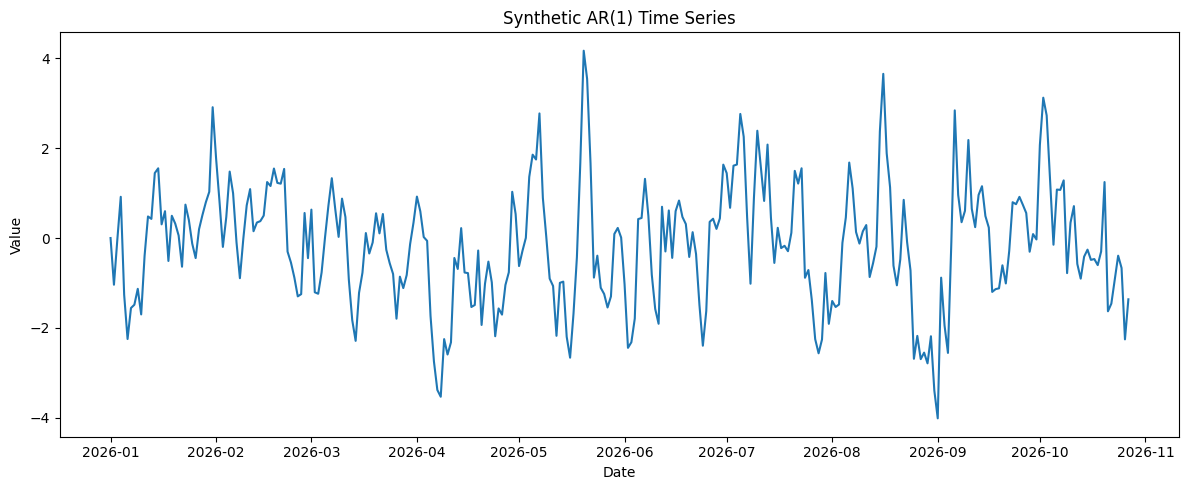

In [3]:
plt.figure(figsize=(12,5))
plt.plot(df["date"], df["value"])
plt.xlabel("Date")
plt.ylabel("Value")
plt.title("Synthetic AR(1) Time Series")
plt.tight_layout()
plt.show()


## 3. What is autocorrelation?

Autocorrelation measures how strongly a series is related to its own past values.

Examples:

`Lag 1` → today vs yesterday

`Lag 2` → today vs two days ago

`Lag 7` → today vs seven days ago


In [4]:
for lag in [1, 2, 3, 7]:
    corr = df["value"].autocorr(lag=lag)
    print(f"Lag {lag} autocorrelation: {corr:.3f}")


Lag 1 autocorrelation: 0.722
Lag 2 autocorrelation: 0.446
Lag 3 autocorrelation: 0.251
Lag 7 autocorrelation: 0.002


## 4. ACF — Autocorrelation Function

ACF plots correlation across many lags at once.

It answers:

> How correlated is today's value with values 1, 2, 3, ... steps in the past?


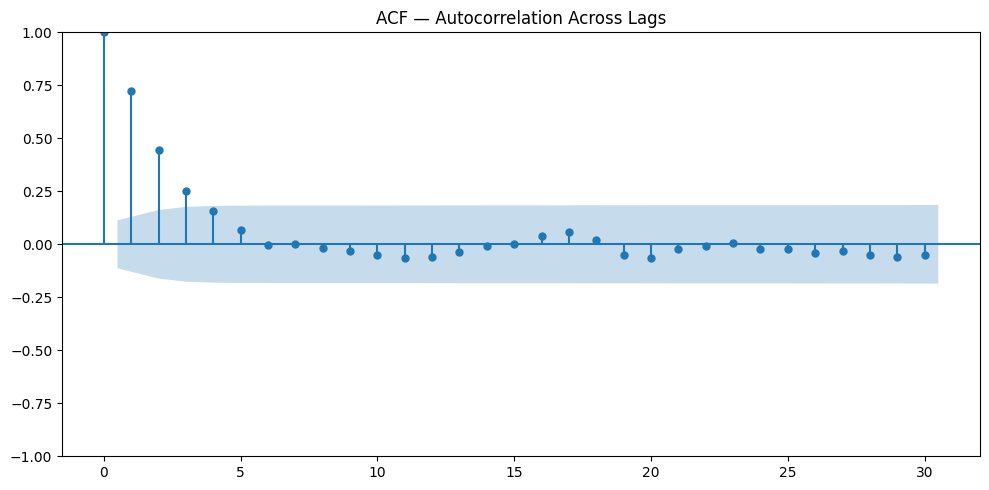

In [5]:
fig, ax = plt.subplots(figsize=(10,5))

plot_acf(
    df["value"],
    lags=30,
    ax=ax
)

ax.set_title("ACF — Autocorrelation Across Lags")
plt.tight_layout()
plt.show()


## 5. Reading the ACF plot

Each vertical bar represents the autocorrelation at one lag.

The shaded area is an approximate confidence interval.

Bars clearly outside the interval suggest statistically meaningful autocorrelation.


## 6. Why PACF is needed

Suppose today depends on yesterday, and yesterday depends on two days ago.

Then today can appear correlated with two days ago indirectly.

PACF tries to remove that indirect effect.


## 7. PACF — Partial Autocorrelation Function

PACF measures the **direct** relationship between the current value and a specific lag after accounting for shorter lags.

For lag 2:

ACF asks:

> Is today related to two days ago?

PACF asks:

> Is today still directly related to two days ago after accounting for yesterday?


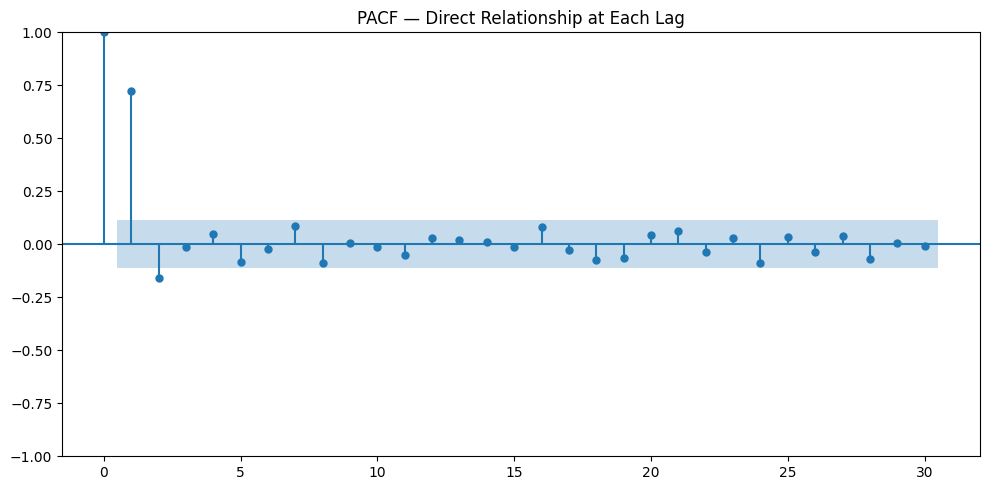

In [6]:
fig, ax = plt.subplots(figsize=(10,5))

plot_pacf(
    df["value"],
    lags=30,
    method="ywm",
    ax=ax
)

ax.set_title("PACF — Direct Relationship at Each Lag")
plt.tight_layout()
plt.show()


## 8. Why this example is useful

We created an **AR(1)** process:

`y_t = 0.75 × y_(t-1) + noise`

So the strongest direct relationship should be at:

`Lag 1`

The PACF should show a strong spike at lag 1 and much weaker direct relationships afterward.

The ACF can decay more gradually because dependence propagates through previous observations.


## 9. ACF vs PACF

### ACF
Measures the total relationship with each lag.

Includes:
- direct effects
- indirect effects

### PACF
Measures the direct relationship after controlling for intermediate lags.

Simple intuition:

**ACF = total relationship**

**PACF = direct relationship**


## 10. Why these plots matter for ARIMA

ACF and PACF are traditionally used to help choose ARIMA parameters.

Very simplified intuition:

### AR(p)
Uses previous values.

PACF can help suggest the order `p`.

### MA(q)
Uses previous forecast errors.

ACF can help suggest the order `q`.

These are heuristics, not rigid rules.


## 11. Seasonal structure in ACF

If daily demand repeats every 7 days, ACF may show repeated spikes at:

`Lag 7`

`Lag 14`

`Lag 21`

This can indicate weekly seasonality.


## Enterprise intuition

ACF and PACF can help analyze:

- demand forecasting
- infrastructure traffic
- transaction volumes
- sensor readings
- workload patterns
- recurring customer behavior

They help reveal whether recent history or seasonal history contains useful predictive signal.


## Important caution

ACF and PACF should not be interpreted mechanically.

Trend and non-stationarity can create high autocorrelation across many lags.

That is why stationarity matters before interpreting these plots.

Real systems may also contain structural breaks, changing variance, multiple seasonalities, and nonlinear relationships.


## What does this teach?

- Autocorrelation measures how a series relates to its own past.
- ACF shows total correlation across lags.
- PACF isolates direct relationships.
- Seasonal patterns can appear as repeating ACF spikes.
- PACF can help suggest AR order.
- ACF can help suggest MA order.
- These are diagnostic tools, not automatic model-selection rules.

> **ACF asks: how much is the past related to today? PACF asks: which past values still matter directly after accounting for everything in between?**


## References

- https://www.statsmodels.org/stable/generated/statsmodels.graphics.tsaplots.plot_acf.html
- https://www.statsmodels.org/stable/generated/statsmodels.graphics.tsaplots.plot_pacf.html
- https://otexts.com/fpp3/acf.html
- https://otexts.com/fpp3/arima.html
